In [81]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [82]:
# Load CSV
teams = pd.read_csv("../basketballPlayoffs/teams.csv")

In [83]:
# Alternatively, display only columns that contain null values
null_columns = null_counts[null_counts > 0]
print("\nColumns with null values:")
print(null_columns)



Columns with null values:
divID         142
firstRound     62
semis         104
finals        122
dtype: int64


In [86]:
# List of columns to check for maximum values
columns_to_check = ["o_fgm","o_fga","o_ftm","o_fta","o_3pm","o_3pa","o_oreb","o_dreb",
                    "o_reb","o_asts","o_pf","o_stl","o_to","o_blk","o_pts","d_fgm","d_fga",
                    "d_ftm","d_fta","d_3pm","d_3pa","d_oreb","d_dreb","d_reb","d_asts","d_pf",
                    "d_stl","d_to","d_blk","d_pts","tmORB","tmDRB","tmTRB","opptmORB","opptmDRB",
                    "opptmTRB","won","lost","GP","homeW","homeL","awayW","awayL","confW","confL",
                    "min","attend"]

# Dictionary to store the team with the max value for each statistic and the corresponding year
max_teams = {}

# Find the team with the maximum value for each statistic and the year for that max value
for column in columns_to_check:
    # Get the team-year combination with the maximum value for the column
    max_team_year = teams.loc[teams[column].idxmax()]  # Get the row with the max value for the statistic
    max_team = max_team_year["tmID"]                    # Team with max value
    max_year = max_team_year["year"]                    # Year of the max value
    max_value = max_team_year[column]                   # Max value for that statistic
    
    max_teams[column] = (max_team, max_year, max_value) # Store team, year, and max value

# Display the results
for stat, (team, year, value) in max_teams.items():
    print(f"Team with max {stat}: {team}, Year: {year}, Max Value: {value}")


Team with max o_fgm: PHO, Year: 10, Max Value: 1128
Team with max o_fga: PHO, Year: 9, Max Value: 2485
Team with max o_ftm: WAS, Year: 8, Max Value: 668
Team with max o_fta: DET, Year: 4, Max Value: 882
Team with max o_3pm: PHO, Year: 8, Max Value: 283
Team with max o_3pa: PHO, Year: 8, Max Value: 802
Team with max o_oreb: SAC, Year: 8, Max Value: 452
Team with max o_dreb: DET, Year: 8, Max Value: 931
Team with max o_reb: DET, Year: 8, Max Value: 1311
Team with max o_asts: PHO, Year: 8, Max Value: 683
Team with max o_pf: ATL, Year: 9, Max Value: 796
Team with max o_stl: IND, Year: 10, Max Value: 373
Team with max o_to: WAS, Year: 9, Max Value: 637
Team with max o_blk: LAS, Year: 9, Max Value: 216
Team with max o_pts: PHO, Year: 10, Max Value: 3156
Team with max d_fgm: PHO, Year: 10, Max Value: 1094
Team with max d_fga: PHO, Year: 10, Max Value: 2582
Team with max d_ftm: PHO, Year: 9, Max Value: 694
Team with max d_fta: PHO, Year: 9, Max Value: 932
Team with max d_3pm: PHO, Year: 8, Max

In [87]:
# List of columns to check for maximum summed values
columns_to_check = ["o_fgm","o_fga","o_ftm","o_fta","o_3pm","o_3pa","o_oreb","o_dreb",
                    "o_reb","o_asts","o_pf","o_stl","o_to","o_blk","o_pts","d_fgm","d_fga",
                    "d_ftm","d_fta","d_3pm","d_3pa","d_oreb","d_dreb","d_reb","d_asts","d_pf",
                    "d_stl","d_to","d_blk","d_pts","tmORB","tmDRB","tmTRB","opptmORB","opptmDRB",
                    "opptmTRB","won","lost","GP","homeW","homeL","awayW","awayL","confW","confL",
                    "min","attend"]

# Group by tmID and sum the statistics over all years
team_summed_stats = teams.groupby('tmID')[columns_to_check].sum()

# Dictionary to store the team with the max summed value for each statistic
max_teams = {}

# Find the team with the maximum summed value for each statistic
for column in columns_to_check:
    # Get the team with the max summed value for the column
    max_team = team_summed_stats[column].idxmax()  # Team with max value for the column
    max_value = team_summed_stats[column].max()    # Max summed value for the column
    max_teams[column] = (max_team, max_value)      # Store team and max value

# Display the results
for stat, (team, value) in max_teams.items():
    print(f"Team with max summed {stat}: {team}, Summed Value: {value}")


Team with max summed o_fgm: LAS, Summed Value: 9168
Team with max summed o_fga: PHO, Summed Value: 21386
Team with max summed o_ftm: DET, Summed Value: 5335
Team with max summed o_fta: DET, Summed Value: 7336
Team with max summed o_3pm: NYL, Summed Value: 2017
Team with max summed o_3pa: NYL, Summed Value: 5653
Team with max summed o_oreb: SAC, Summed Value: 3819
Team with max summed o_dreb: LAS, Summed Value: 8071
Team with max summed o_reb: DET, Summed Value: 11695
Team with max summed o_asts: LAS, Summed Value: 5893
Team with max summed o_pf: PHO, Summed Value: 6920
Team with max summed o_stl: IND, Summed Value: 3036
Team with max summed o_to: DET, Summed Value: 5404
Team with max summed o_blk: LAS, Summed Value: 1518
Team with max summed o_pts: PHO, Summed Value: 25307
Team with max summed d_fgm: PHO, Summed Value: 9056
Team with max summed d_fga: PHO, Summed Value: 21223
Team with max summed d_ftm: PHO, Summed Value: 5374
Team with max summed d_fta: PHO, Summed Value: 7187
Team wi

In [73]:
# Teams playing per year

teams_per_year = teams.groupby('year')['tmID'].nunique()
print(teams_per_year)

print('\n')


 # List Teams That Qualify For Offs and the Respective Winner for each year
playoff_teams = teams[(teams['year'].between(1, 10)) & (teams['playoff'] == "Y")]

teams_by_year = {}
for year, group in playoff_teams.groupby('year'):
    teams = group['name'].tolist()
    winner = group.loc[group['finals'] == "W", 'name'].tolist()
    winning_team = winner[0] if winner else "No winner listed"
    teams_by_year[year] = {
        "teams": teams,
        "winner": winning_team
    }
for year, info in teams_by_year.items():
    print(f"Year {year}: Teams - {info['teams']}, Winner - {info['winner']}")


# Fica para pensar adicionar uma coluna nas equipas em que ponho "won last year" porque se ganhou as finals é muito provavel que no ano seguinte esteja automaticamente nos offs, isso confirma-se em praticamente todos os anos da lista
# É uma prediction automatica



year
1     16
2     16
3     16
4     14
5     13
6     13
7     14
8     13
9     14
10    13
Name: tmID, dtype: int64


Year 1: Teams - ['Cleveland Rockers', 'Houston Comets', 'Los Angeles Sparks', 'New York Liberty', 'Orlando Miracle', 'Phoenix Mercury', 'Sacramento Monarchs', 'Washington Mystics'], Winner - Houston Comets
Year 2: Teams - ['Charlotte Sting', 'Cleveland Rockers', 'Houston Comets', 'Los Angeles Sparks', 'Miami Sol', 'New York Liberty', 'Sacramento Monarchs', 'Utah Starzz'], Winner - Los Angeles Sparks
Year 3: Teams - ['Charlotte Sting', 'Houston Comets', 'Indiana Fever', 'Los Angeles Sparks', 'New York Liberty', 'Seattle Storm', 'Utah Starzz', 'Washington Mystics'], Winner - Los Angeles Sparks
Year 4: Teams - ['Charlotte Sting', 'Cleveland Rockers', 'Connecticut Sun', 'Detroit Shock', 'Houston Comets', 'Los Angeles Sparks', 'Minnesota Lynx', 'Sacramento Monarchs'], Winner - Detroit Shock
Year 5: Teams - ['Connecticut Sun', 'Detroit Shock', 'Los Angeles Sparks', 'Minne

In [74]:
# Load CSV
teams = pd.read_csv("../basketballPlayoffs/teams.csv")

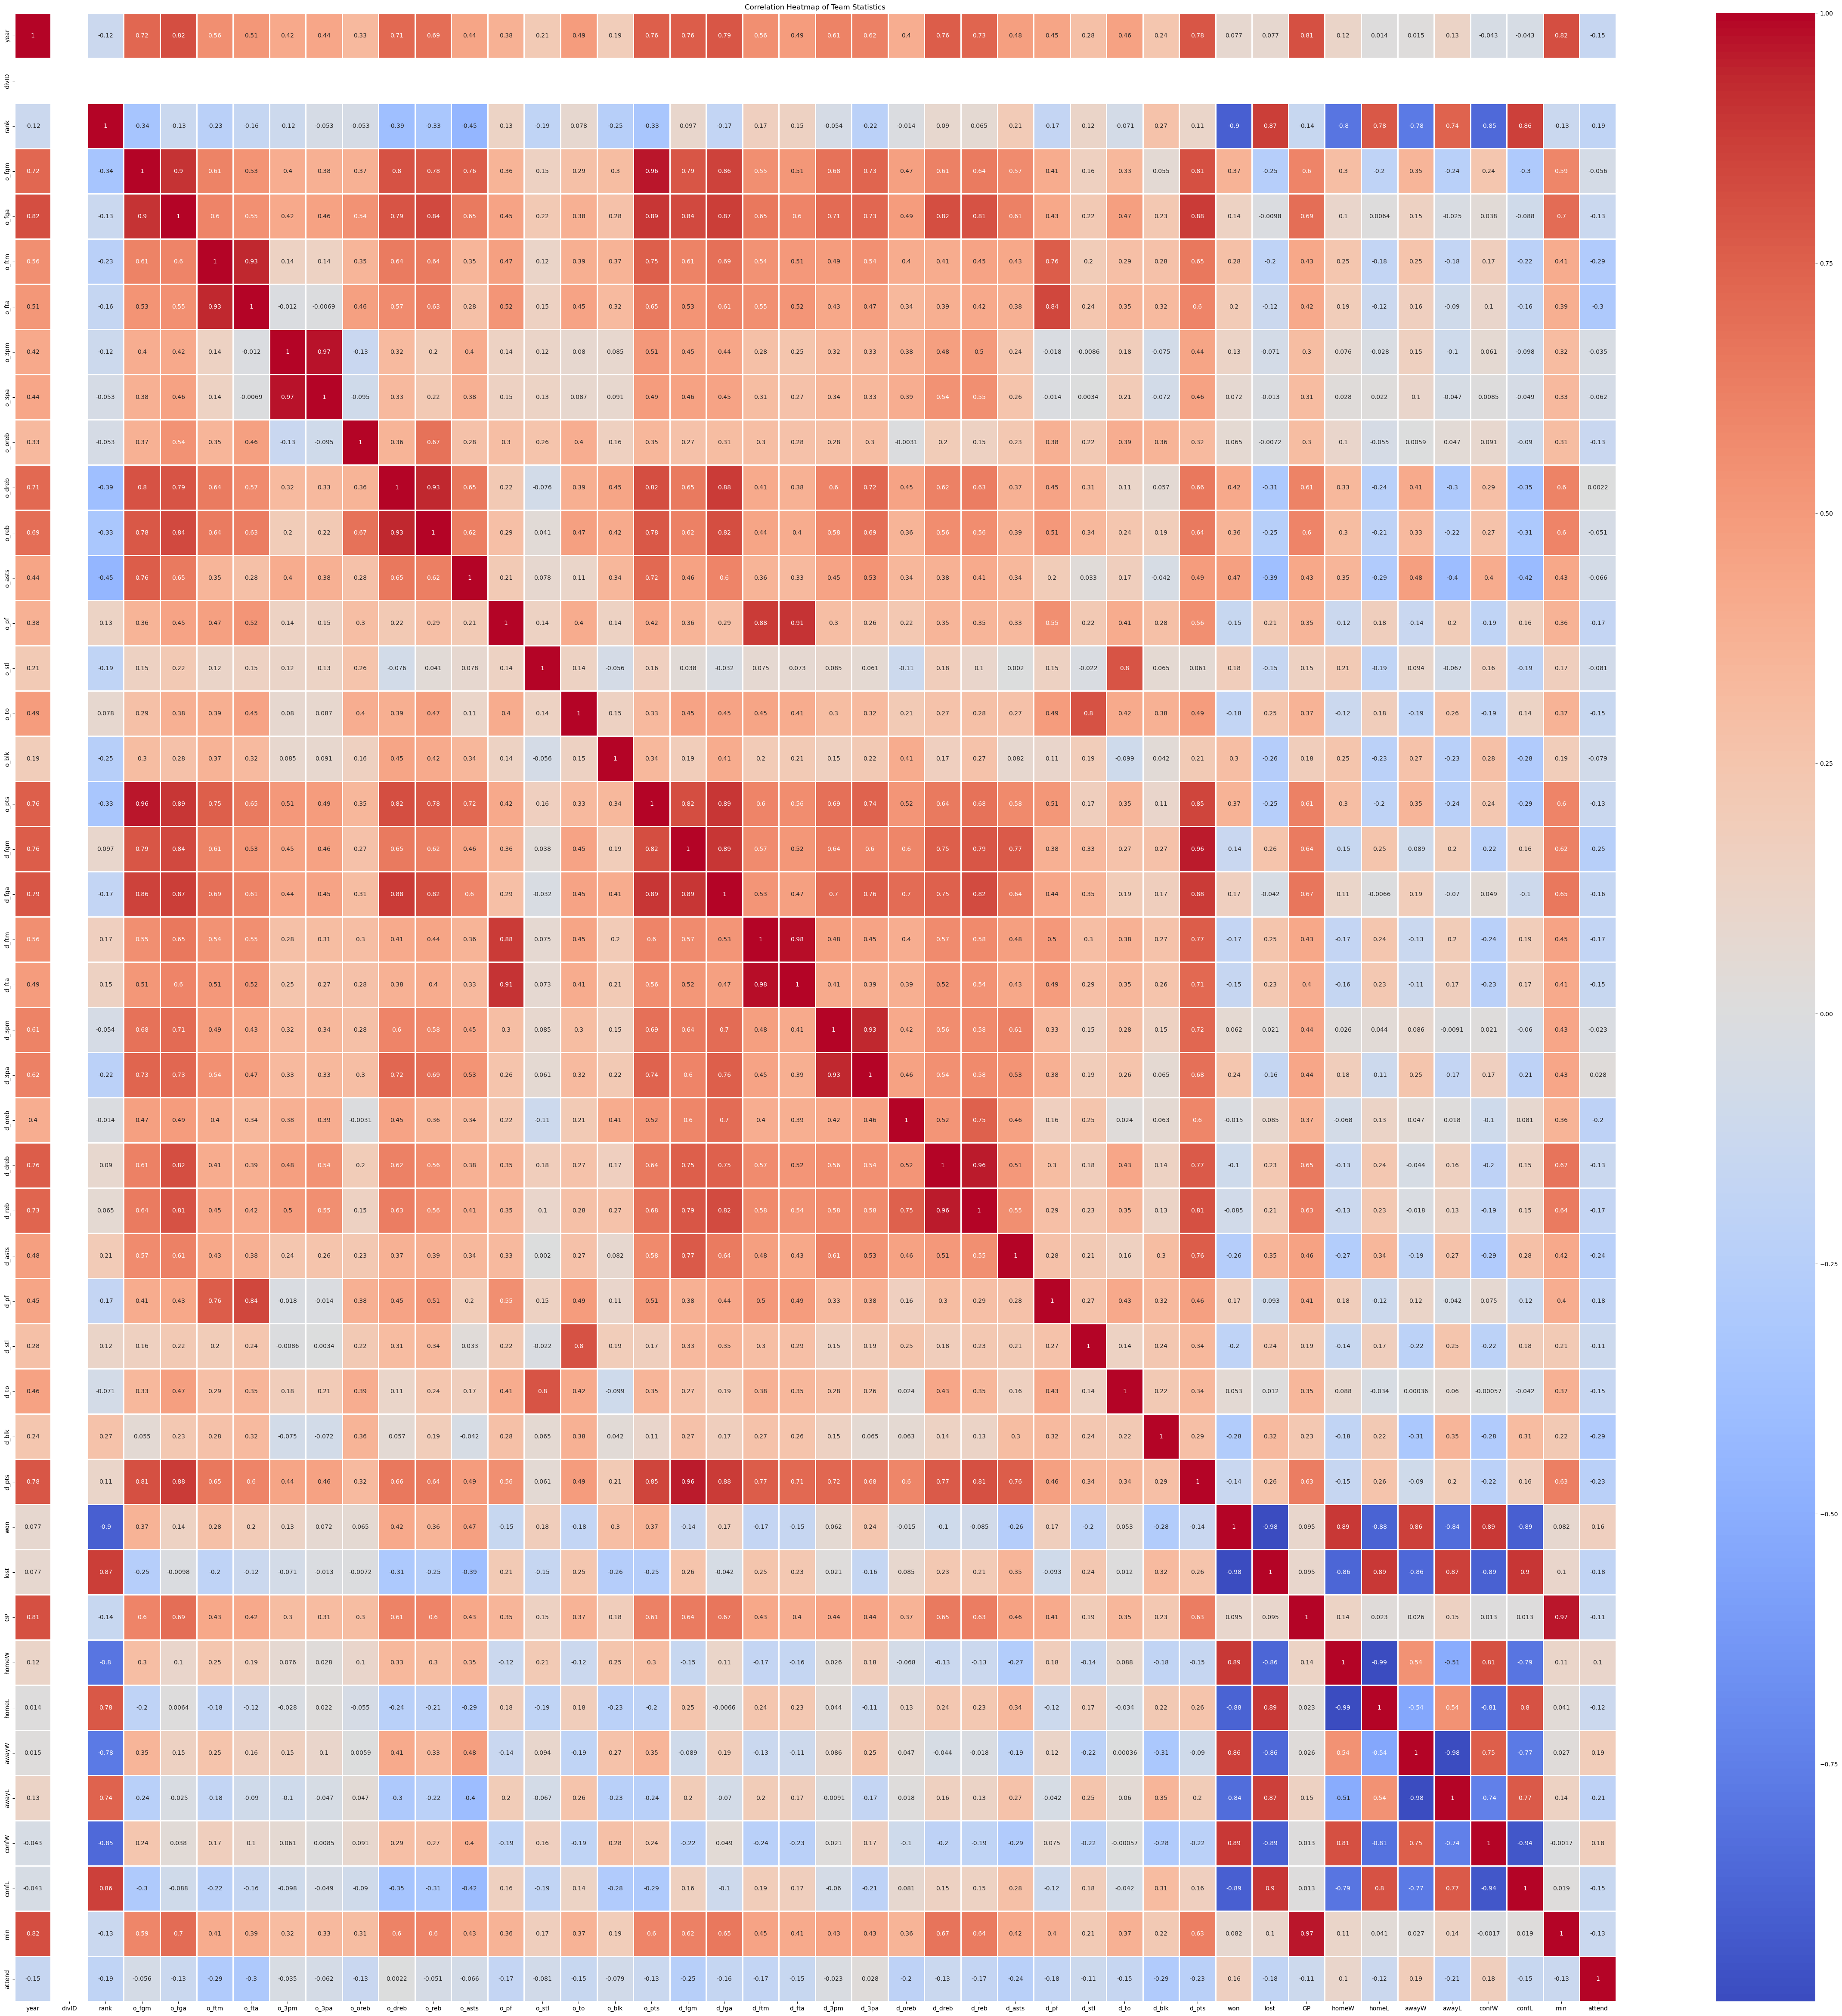

In [75]:
teams = teams.loc[:, (teams != 0).any(axis=0)] # Eliminar Noisy Columns (que so têm 0)


data_numeric=teams.select_dtypes(['number'])
correlation_matrix = data_numeric.corr()

plt.figure(figsize=(60, 60))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", linewidths=1)
plt.title("Correlation Heatmap of Team Statistics")
plt.show()

In [76]:
teams['PPG'] = teams['o_pts'] / teams['GP']
fig = px.line(teams, x='year', y='PPG', color='name', markers=True,  hover_data={'year': True, 'PPG': True, 'won': True, 'lost': True, 'GP': True}, title="Points Per Game (PPG) Over Years by Team")
fig.update_layout(xaxis_title="Year",yaxis_title="Points Per Game (PPG)",legend_title="Team Name")
fig.show()

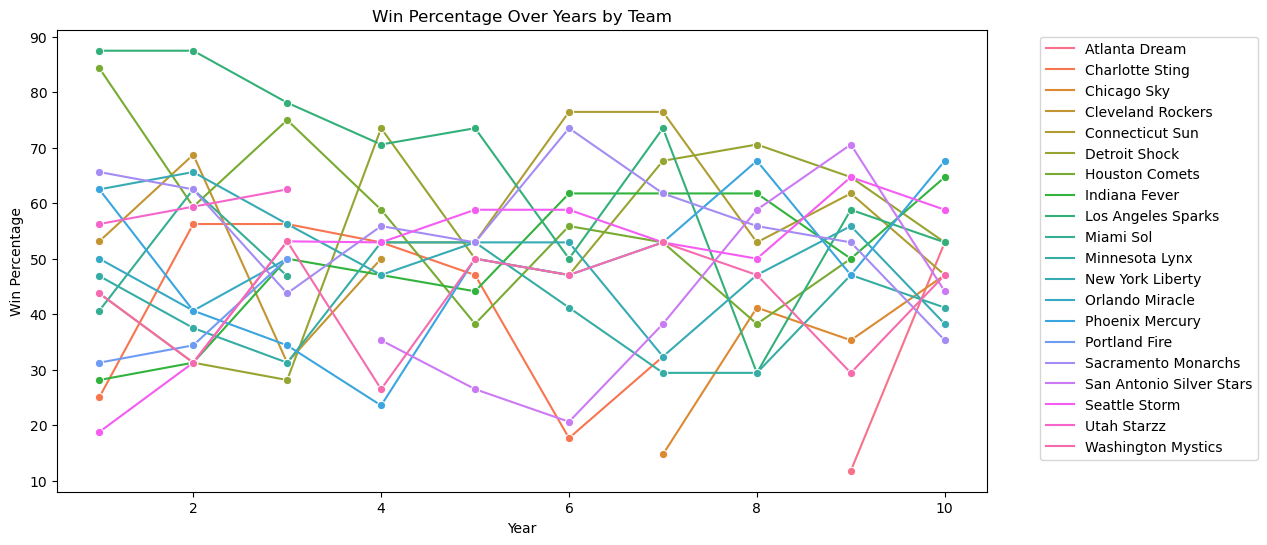

In [77]:
teams['Win_Percentage'] = teams['won'] / teams['GP'] * 100
plt.figure(figsize=(12, 6))
sns.lineplot(data=teams, x='year', y='Win_Percentage', hue='name', marker="o")
plt.title("Win Percentage Over Years by Team")
plt.xlabel("Year")
plt.ylabel("Win Percentage")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

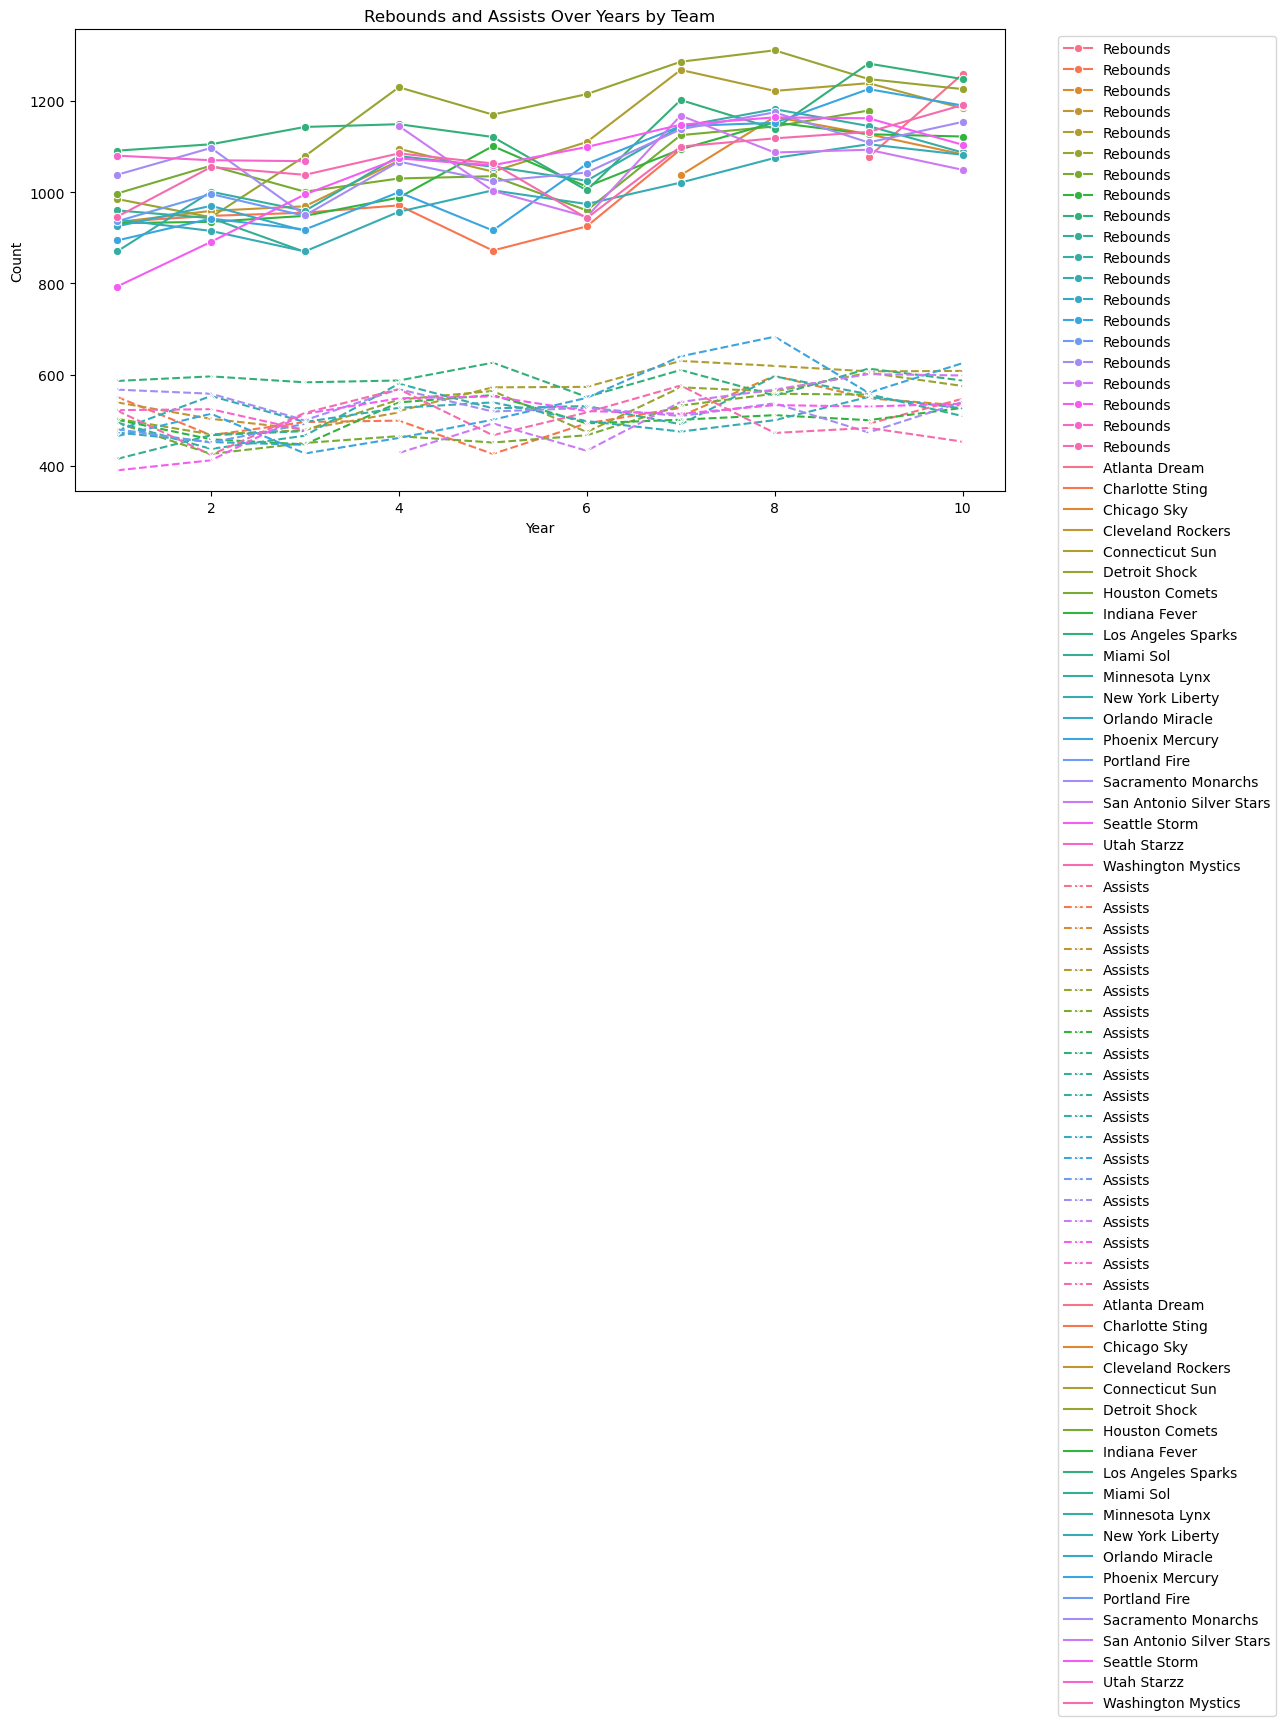

In [78]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=teams, x='year', y='o_reb', hue='name', marker="o", label="Rebounds")
sns.lineplot(data=teams, x='year', y='o_asts', hue='name', marker="x", linestyle="--", label="Assists")
plt.title("Rebounds and Assists Over Years by Team")
plt.xlabel("Year")
plt.ylabel("Count")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [79]:
teams['Home_Win_Percentage'] = teams['homeW'] / (teams['homeW'] + teams['homeL']) * 100
teams['Away_Win_Percentage'] = teams['awayW'] / (teams['awayW'] + teams['awayL']) * 100
fig = px.scatter(teams, x='Home_Win_Percentage',  y='Away_Win_Percentage', color='name', hover_data=['year', 'won', 'lost', 'GP'])
fig.update_layout(xaxis_title="Home Win Percentage",yaxis_title="Away Win Percentage",legend_title="Team Name")
fig.show()

In [80]:
fig = px.line(teams, x='year', y='attend', color='name', markers=True,  hover_data={'year': True, 'attend': True, 'name': True},  title="Attendance Over Years by Team")
fig.update_layout(xaxis_title="Year",yaxis_title="Attendance",legend_title="Team Name")
fig.show()